In [8]:
import warnings; warnings.filterwarnings("ignore")
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
SEED = 42
%matplotlib inline

In [9]:
import os
df = pd.read_csv("D:/major-project/The-Major-project-addict/smartphone-usage-and-addiction-prediction/versions/1/Smartphone_Usage_And_Addiction_Analysis_7500_Rows.csv")
df["addiction_level"] = df["addiction_level"].fillna("None")


X = df.drop(columns=["transaction_id", "user_id", "addicted_label","addiction_level"])
y = df["addicted_label"]

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

cat_cols = ["gender", "stress_level", "academic_work_impact"]
num_cols = [c for c in X.columns if c not in cat_cols]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])

preprocessor.fit(X_train)                  # learn the categories (training data only)
encoded = preprocessor.transform(X_train)

In [ ]:
pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(random_state=SEED)),
])

param_grid = {
    "model__n_estimators": [300],
    "model__max_depth": [8, None],
    "model__min_samples_leaf": [5, 10, 20],
}

gsb = GridSearchCV(pipe, param_grid, scoring="accuracy", cv=5, n_jobs=-1).fit(X_train, y_train)

    # full pipeline
pb = gsb.predict(X_test)

baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"accuracy: {accuracy_score(y_test, pb):.4f}  (majority baseline {baseline:.3f})\n")
print(classification_report(y_test, pb, target_names=["Not addicted", "Addicted"], digits=3))

Binary test accuracy: 0.9220  (majority baseline 0.696)

              precision    recall  f1-score   support

Not addicted      0.857     0.893     0.874       456
    Addicted      0.952     0.935     0.943      1044

    accuracy                          0.922      1500
   macro avg      0.905     0.914     0.909      1500
weighted avg      0.923     0.922     0.922      1500



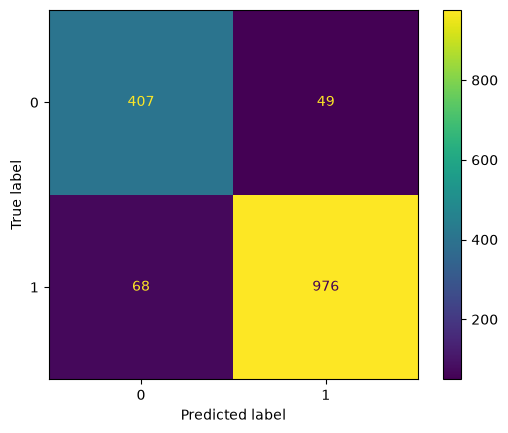

In [15]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, f1_score)

ConfusionMatrixDisplay.from_estimator(gsb, X_test, y_test)
plt.show()